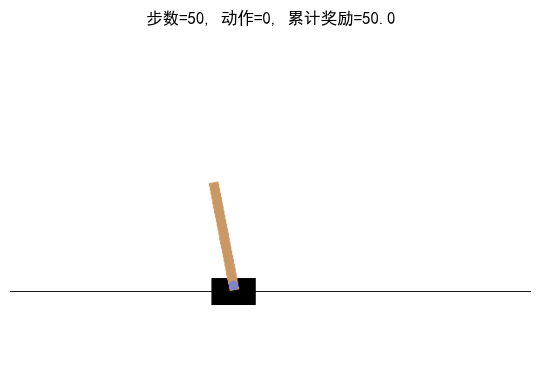

回合结束！总步数=50, 累计奖励=50.00
终止原因: 被截断(超时)


In [ ]:
import gymnasium as gym
import matplotlib.pyplot as plt
from IPython import display
import time

plt.rcParams["font.sans-serif"] = ["SimHei"]
plt.rcParams["axes.unicode_minus"] = False

# 创建环境，自行结束
# env = gym.make("CartPole-v1", render_mode="rgb_array")

# 截断环境的最大步数为50步
env = gym.make("CartPole-v1", render_mode="rgb_array", max_episode_steps=50)
obs, info = env.reset()

# 准备画布
fig, ax = plt.subplots(figsize=(6, 4))
img = ax.imshow(env.render())
ax.axis("off")
ax.set_title("CartPole - 自动随机运行中")
plt.tight_layout()
display.display(fig)

total_reward = 0.0
step = 0

# 自动随机运行直到回合结束
while True:
    action = env.action_space.sample()
    obs, reward, terminated, truncated, info = env.step(action)
    total_reward += reward
    step += 1

    img.set_data(env.render())
    ax.set_title(f"步数={step}, 动作={action}, 累计奖励={total_reward:.1f}")
    display.clear_output(wait=True)
    display.display(fig)
    time.sleep(0.03)

    if terminated or truncated:
        break

print(f"回合结束！总步数={step}, 累计奖励={total_reward:.2f}")
print(f"终止原因: {'自然结束' if terminated else '被截断(超时)'}")

env.close()
plt.close(fig)